# OAQ low-cost sensors vs the nearest CPCB station

[OAQ](https://oaq.notf.in) publishes readings of low-cost PM2.5 sensors (Airnet, Aurassure). OAQ also publishes a copy of the CPCB reference stations. This notebook does these steps:

1. It lists the OAQ sensors and counts the low-cost sensors in each city.
2. It finds the length of the OAQ history and examines the plausibility of the low-cost records.
3. It compares the daily records of OAQ with the 15-minute readings of OAQ.
4. It compares the Airnet sensors in Bengaluru with their nearest CPCB station. For this comparison, it uses the official 15-minute data of CPCB.

A table or a plot comes before each statement. For a full examination of the quality of the Airnet sensors, refer to the notebook *Quality assessment of OAQ Airnet sensors*. You must set `OAQ_API_KEY` for the OAQ calls.

In [1]:
import pandas as pd

from vayuayan import (
    CPCBHistorical,
    OAQClient,
    oaq_city_tally,
    oaq_nearest_cpcb,
    plot_daily_record_day,
    plot_sensor_vs_reference,
    readings_mean,
    sensor_accuracy,
    sensor_plausibility,
    set_theme,
)

set_theme()
pd.set_option("display.width", 160)
oaq = OAQClient()
cpcb = CPCBHistorical()

## 1. OAQ sensors, and the low-cost sensors in each city

`OAQClient.sensors()` lists all the providers. The value of `type` shows which sensors are the OAQ copy of the CPCB reference stations and which sensors are low-cost sensors.

In [2]:
sensors = oaq.sensors()
sensors.groupby(["provider", "type"]).size().rename("sensors").to_frame()

,,sensors
provider,type,
airnet,Sensor,47
aurassure,Sensor,21
cpcb,Reference Station,624


`oaq_city_tally` counts the sensors that are not in the OAQ copy of CPCB. For each city, it also gives the CPCB stations and the median distance to the nearest CPCB station. The CPCB stations come from the station directory that is part of vayuayan.

In [3]:
tally = oaq_city_tally(sensors)
no_cpcb = tally[tally.cpcb_stations == 0]
print(
    f"{no_cpcb.sensors.sum()} low-cost sensors in {len(no_cpcb)} places with no CPCB station: "
    + ", ".join(no_cpcb.city)
)
tally.round(1)

7 low-cost sensors in 7 places with no CPCB station: Burla, Jatni, Kakudia, Korapalli, Kuniyamuthur, Nuapada, Singanallur


,city,provider,sensors,cpcb_stations,median_km_to_cpcb
0,Bengaluru,airnet,47,14,2.3
1,Siliguri,aurassure,4,1,4.7
2,Bhubaneswar,aurassure,3,2,4.6
3,Coimbatore,aurassure,2,2,5.5
4,Barbil,aurassure,1,1,3.5
5,Baripada,aurassure,1,1,4.3
6,Bengaluru,aurassure,1,14,0.8
7,Burla,aurassure,1,0,35.9
8,Cuttack,aurassure,1,1,6.5
9,Jatni,aurassure,1,0,15.4


## 2. History and plausibility of the records

The code that follows uses the daily records of OAQ (`OAQClient.daily_records`). It uses all the Airnet and Aurassure sensors and 40 random CPCB stations. It shows the first day of each sensor.

In [4]:
cpcb_sample = sensors.query("provider == 'cpcb'").sample(40, random_state=1)
low_cost = sensors[sensors.type != "Reference Station"]
records = pd.concat(
    [
        oaq.daily_records(
            "airnet", low_cost.query("provider == 'airnet'")["id"], range(2020, 2027)
        ).assign(provider="airnet"),
        oaq.daily_records(
            "aurassure",
            low_cost.query("provider == 'aurassure'")["id"],
            range(2020, 2027),
        ).assign(provider="aurassure"),
        oaq.daily_records("cpcb", cpcb_sample["id"], range(2015, 2027)).assign(
            provider="cpcb"
        ),
    ],
    ignore_index=True,
)
first = (
    records.assign(date=pd.to_datetime(records.date))
    .groupby(["provider", "sensor_id"])
    .date.min()
    .reset_index()
)
first.groupby("provider").date.agg(
    sensors="size", earliest="min", median_first_day="median"
)

,sensors,earliest,median_first_day
provider,,,
airnet,47,2026-01-01,2026-01-01
aurassure,21,2025-02-01,2025-02-01
cpcb,40,2021-01-01,2022-08-20


`sensor_plausibility` sets flags on the low-cost daily records. It sets a flag for these conditions:

- PM2.5 equal to 0.
- A temperature of more than 50 °C.
- A humidity of 100 %.
- The same PM2.5 on two days, one after the other (`stuck_run=2`).

A flag shows a record that you must examine. A flag does not always show a fault. A humidity of 100 % can be a correct value during the monsoon. In these cities, a temperature of more than 50 °C is not a correct value.

In [5]:
lc = records[records.provider != "cpcb"]
checks = {
    "PM2.5 = 0 (%)": sensor_plausibility(lc, "pm25", time_col="date")
    .set_index("sensor_id")
    .zero_pct,
    "PM2.5 same as the day before (%)": sensor_plausibility(
        lc, "pm25", stuck_run=2, time_col="date"
    )
    .set_index("sensor_id")
    .stuck_pct,
    "temp > 50 °C (%)": sensor_plausibility(lc, "temp", max_value=50, time_col="date")
    .set_index("sensor_id")
    .above_max_pct,
    "humidity 100 % (%)": sensor_plausibility(
        lc, "humid", max_value=99.99, time_col="date"
    )
    .set_index("sensor_id")
    .above_max_pct,
}
flags = pd.DataFrame(checks).join(
    lc.groupby("sensor_id").agg(provider=("provider", "first"), days=("date", "size"))
)
flags.groupby("provider").agg(
    sensors=("days", "size"), days=("days", "sum"), **{c: (c, "mean") for c in checks}
).round(2)

,sensors,days,PM2.5 = 0 (%),PM2.5 same as the day before (%),temp > 50 °C (%),humidity 100 % (%)
provider,,,,,,
airnet,43,9914,0.00,0.12,NaN,NaN
aurassure,21,3075,0.18,0.30,1.61,22.7


In [6]:
# Sensors with any record above 50 °C
flags[flags["temp > 50 °C (%)"] > 0].round(1)

,PM2.5 = 0 (%),PM2.5 same as the day before (%),temp > 50 °C (%),humidity 100 % (%),provider,days
sensor_id,,,,,,
14151,2.5,1.2,11.2,47.5,aurassure,160
14217,0.0,0.0,19.8,25.4,aurassure,177
14331,0.0,0.0,2.7,22.7,aurassure,220


## 3. Daily records of OAQ vs the 15-minute readings of OAQ

`OAQClient.check_daily_records` compares each daily record with the mean, the last value and the maximum of the 15-minute readings of that day. The code that follows does this check for 3 random days of each Bengaluru sensor in 2026 (CPCB copy and Airnet):

In [7]:
blr = sensors[sensors.city == "Bengaluru"]
days = pd.concat(
    [
        oaq.daily_records(p, g["id"], [2026]).assign(provider=p)
        for p, g in blr.groupby("provider")
    ]
)
picks = (
    days.dropna(subset=["pm25"])
    .groupby("sensor_id")
    .sample(3, random_state=3, replace=True)
    .drop_duplicates()
)
checked = pd.concat(
    [
        oaq.check_daily_records(p, s, g.date).assign(provider=p)
        for (p, s), g in picks.groupby(["provider", "sensor_id"])
    ],
    ignore_index=True,
)
by_provider = checked.groupby("provider")
(
    100 * by_provider[["record_is_mean", "record_is_last", "record_is_max"]].mean()
).add_suffix(" (%)").assign(sensor_days=by_provider.size()).round(1)

,record_is_mean (%),record_is_last (%),record_is_max (%),sensor_days
provider,,,,
airnet,43.7,54.8,2.4,126
aurassure,33.3,33.3,0.0,3
cpcb,38.9,66.7,8.3,36


The sum of the shares can be more than 100 %. The cause is that on a stable day, the last reading can be equal to the mean. In 2026, the daily record is usually equal to the **last 15-minute reading of the day**, not to the mean of the day.

The notebook *OAQ daily values* does a check of a full year. That check finds the change at approximately 1 March 2026. Before that date, the daily record is the mean.

One day shows the effect. The day is 29 May 2026 at the Kadabesanahalli station of CPCB (`site_164`). The example shows the 15-minute readings of OAQ together with the data of CPCB.

SSL verification failed for airquality.cpcb.gov.in; sending without verification


OAQ readings equal to CPCB's own: 83 of 84
 record  mean  last   max
  368.7  66.3 368.7 827.6


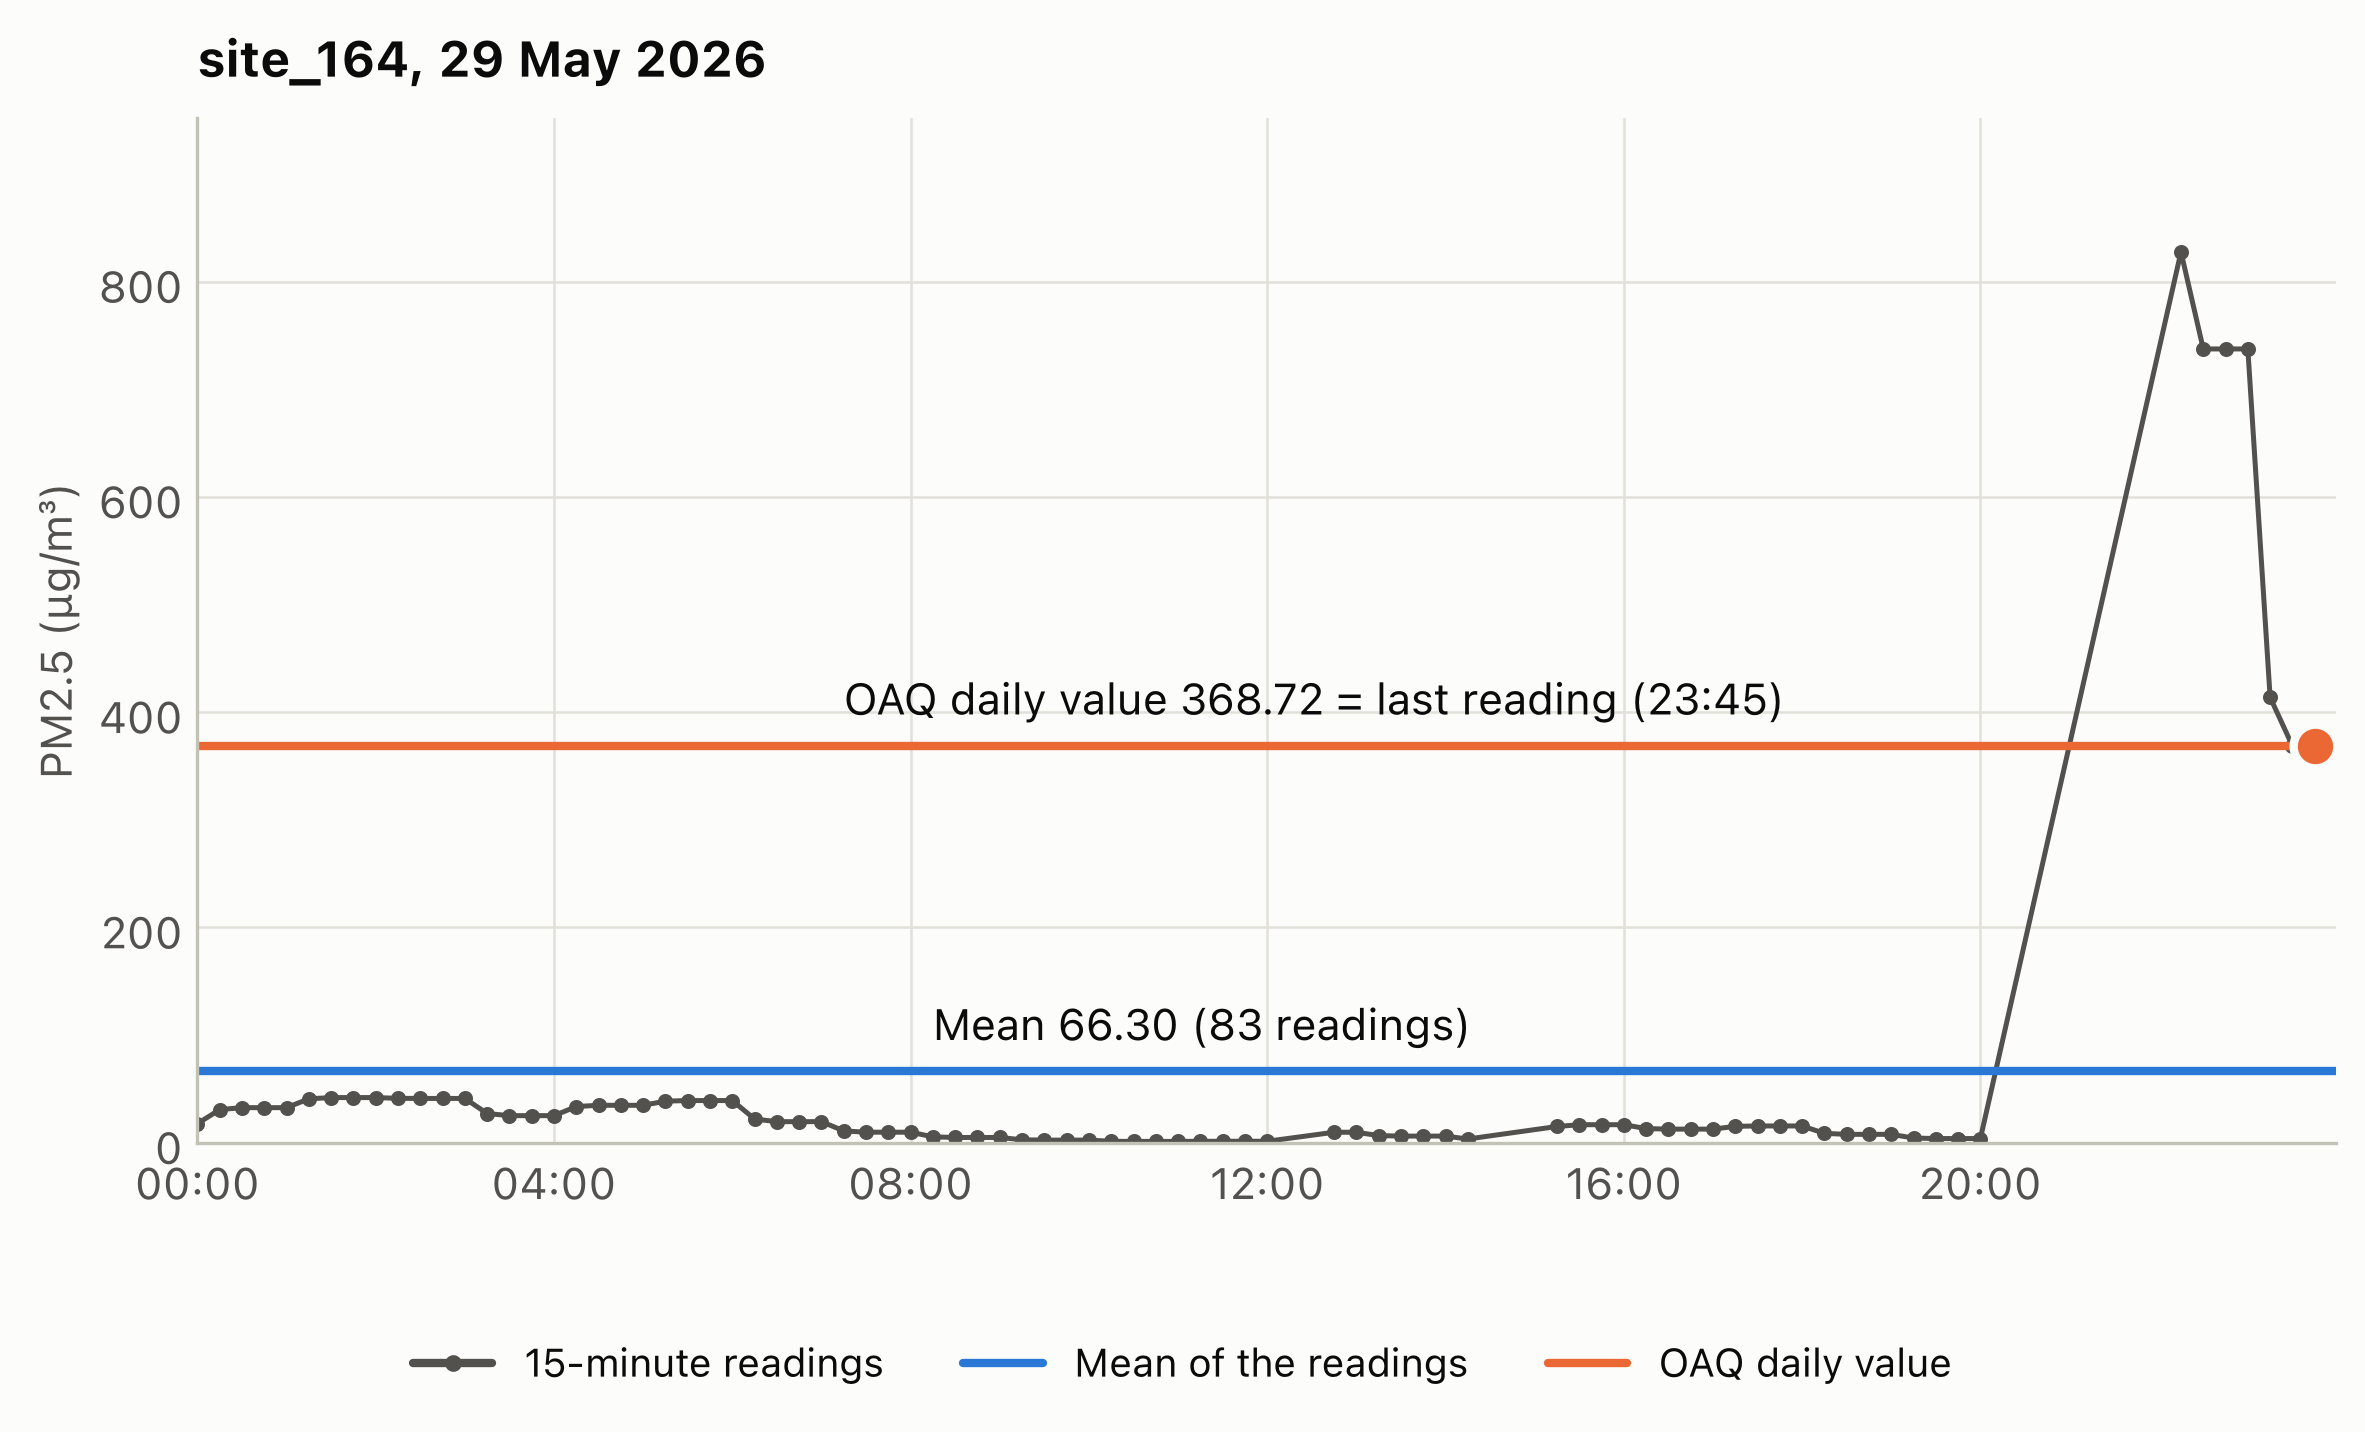

In [8]:
example = oaq.check_daily_records("cpcb", "164", ["2026-05-29"])
day = oaq.readings("cpcb", "164", ["2026-05-29"])
official = cpcb.raw_readings("site_164", 2026, pollutants=["PM2.5"])
same = day.merge(official, on="timestamp")
print(
    f"OAQ readings equal to CPCB's own: {(same.pm25 - same.value).abs().lt(0.01).sum()} of {len(same)}"
)
print(example[["record", "mean", "last", "max"]].round(1).to_string(index=False))
plot_daily_record_day(day, example, title="site_164, 29 May 2026")

The notebook *OAQ daily values* does a check of each day of six sensor-years. It finds the change in the first days of March 2026 for all three providers.


Thus, the daily values must come from the 15-minute readings. `readings_mean` (or `OAQClient.daily_means`) calculates these values. It uses the EPA completeness rule (75 % of the readings).

## 4. Airnet sensors vs their nearest CPCB station (Bengaluru, 2026)

This section uses all the Airnet sensors that are less than 3 km from a CPCB station. The daily means of each sensor and of its station come from 15-minute data. The period is January to September 2026. `sensor_accuracy` gives the fit and the error for each sensor.

In [9]:
airnet = sensors[sensors.provider == "airnet"]
pairs = oaq_nearest_cpcb(airnet, k=1).query("distance_km <= 3")
period = pd.date_range("2026-01-01", "2026-09-30")
daily = readings_mean(oaq.readings("airnet", pairs.sensor_id, period))
raw = cpcb.raw_readings(pairs.cpcb_station_id.unique(), 2026, pollutants=["PM2.5"])
reference = readings_mean(raw, value="value", id_col="station_id").rename(
    columns={"station_id": "cpcb_station_id", "value": "reference"}
)
paired = daily.merge(
    pairs[["sensor_id", "cpcb_station_id", "distance_km"]], on="sensor_id"
).merge(
    reference[["cpcb_station_id", "date", "reference"]], on=["cpcb_station_id", "date"]
)
print(
    f"{len(paired)} sensor-days of {paired.sensor_id.nunique()} sensors, "
    f"{paired.date.min()} to {paired.date.max()}"
)
sensor_accuracy(paired).merge(
    pairs[["sensor_id", "sensor_name", "distance_km"]], on="sensor_id"
).round(2)

770 sensor-days of 15 sensors, 2026-03-03 to 2026-09-30


,sensor_id,days,slope,intercept,r2,rmse,nrmse_pct,slope_ok,intercept_ok,r2_ok,error_ok,targets_met,sensor_name,distance_km
0,12036,134,0.47,16.95,0.76,11.15,42.76,False,False,True,False,1,CSTEP Test Bed,2.25
1,12048,63,0.20,14.76,0.07,23.41,65.75,False,False,False,False,0,Kadubeesanahalli,0.54
2,12065,101,1.32,-12.35,0.48,13.15,41.15,True,False,False,False,1,Jigani Industrial Area-2,1.85
3,12094,38,-0.59,44.54,0.16,19.18,51.09,False,False,False,False,0,Mahadevapura,2.79
4,12096,71,0.81,-0.40,0.61,8.57,37.06,True,True,False,False,2,Byatarayanapura New Extension,0.14
5,12097,100,-0.05,32.48,0.02,18.68,92.85,False,False,False,False,0,CSTEP Test Bed,2.25
6,12100,45,0.89,15.96,0.49,16.15,99.31,True,False,False,False,1,CSTEP Test Bed,2.25
7,12104,41,0.73,11.82,0.44,9.06,59.84,True,False,False,False,1,CSTEP Test Bed,2.25
8,12105,33,1.18,7.21,0.74,10.59,68.05,True,False,True,False,2,CSTEP Test Bed,2.25
9,12107,36,0.90,7.23,0.68,6.43,41.85,True,False,False,True,2,CSTEP Test Bed,2.25


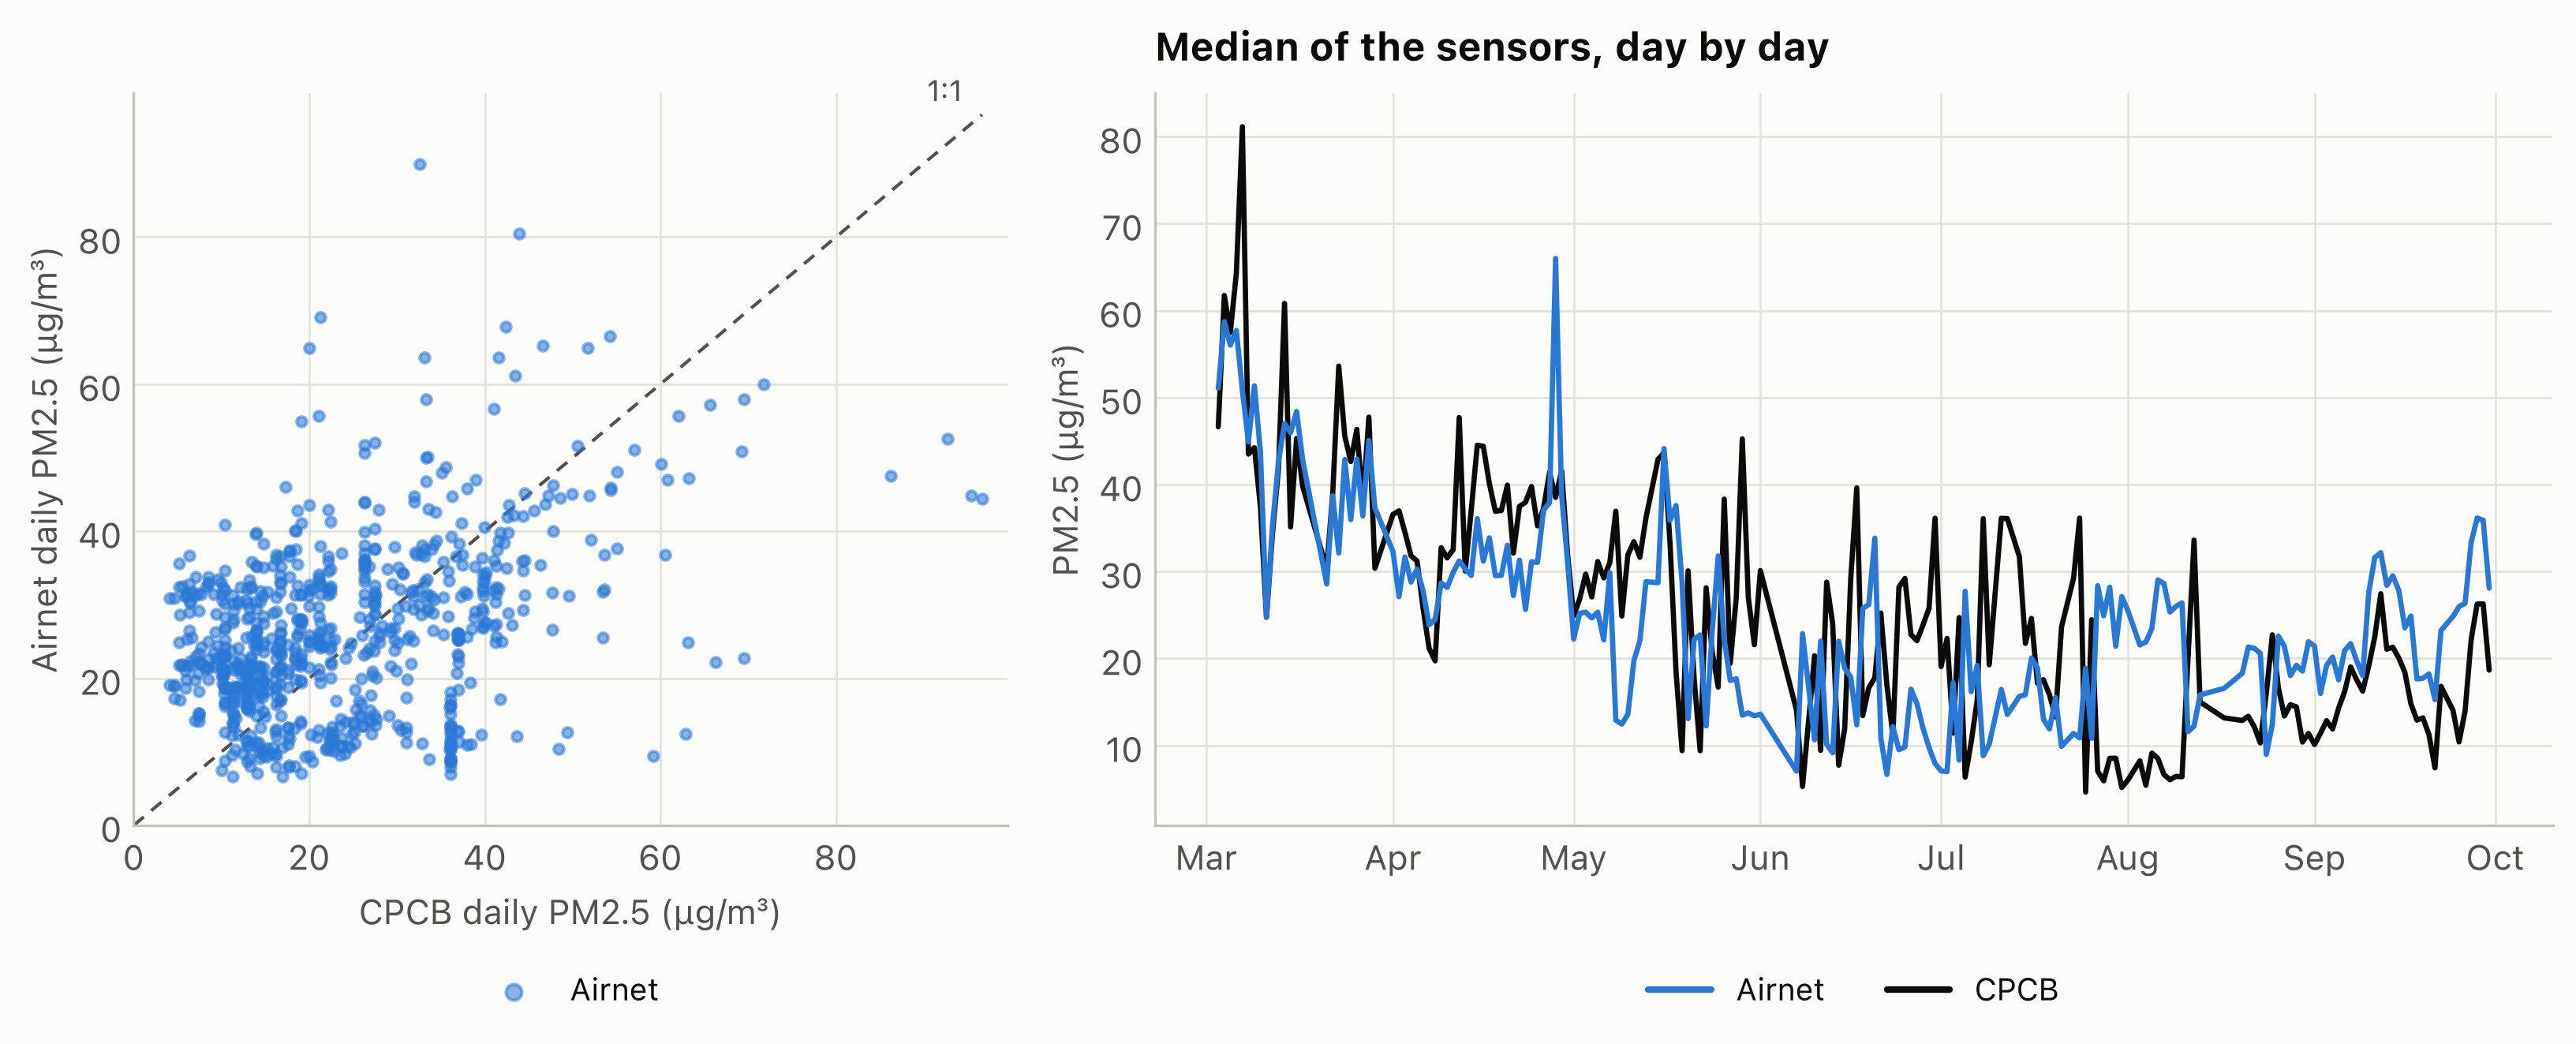

In [10]:
plot_sensor_vs_reference(paired, sensor_label="Airnet", reference_label="CPCB")

### Results with the daily records of OAQ

This part uses the same sensor-days, but with the daily records of OAQ in place of the daily means. The paired days start in March 2026. Thus, most daily records here are the last reading of their day:

In [11]:
recs = oaq.daily_records("airnet", pairs.sensor_id, [2026])[
    ["sensor_id", "date", "pm25"]
]
both = paired.merge(
    recs.rename(columns={"pm25": "record"}), on=["sensor_id", "date"]
).dropna(subset=["record"])
pd.DataFrame(
    {
        "Airnet value": ["daily mean of the 15-minute readings", "OAQ daily record"],
        "r with CPCB": [
            both.pm25.corr(both.reference),
            both.record.corr(both.reference),
        ],
        "median |Airnet - CPCB|": [
            (both.pm25 - both.reference).abs().median(),
            (both.record - both.reference).abs().median(),
        ],
        "sensor-days": [len(both)] * 2,
    }
).round(2)

,Airnet value,r with CPCB,median |Airnet - CPCB|,sensor-days
0,daily mean of the 15-minute readings,0.40,9.62,770
1,OAQ daily record,0.33,10.11,770


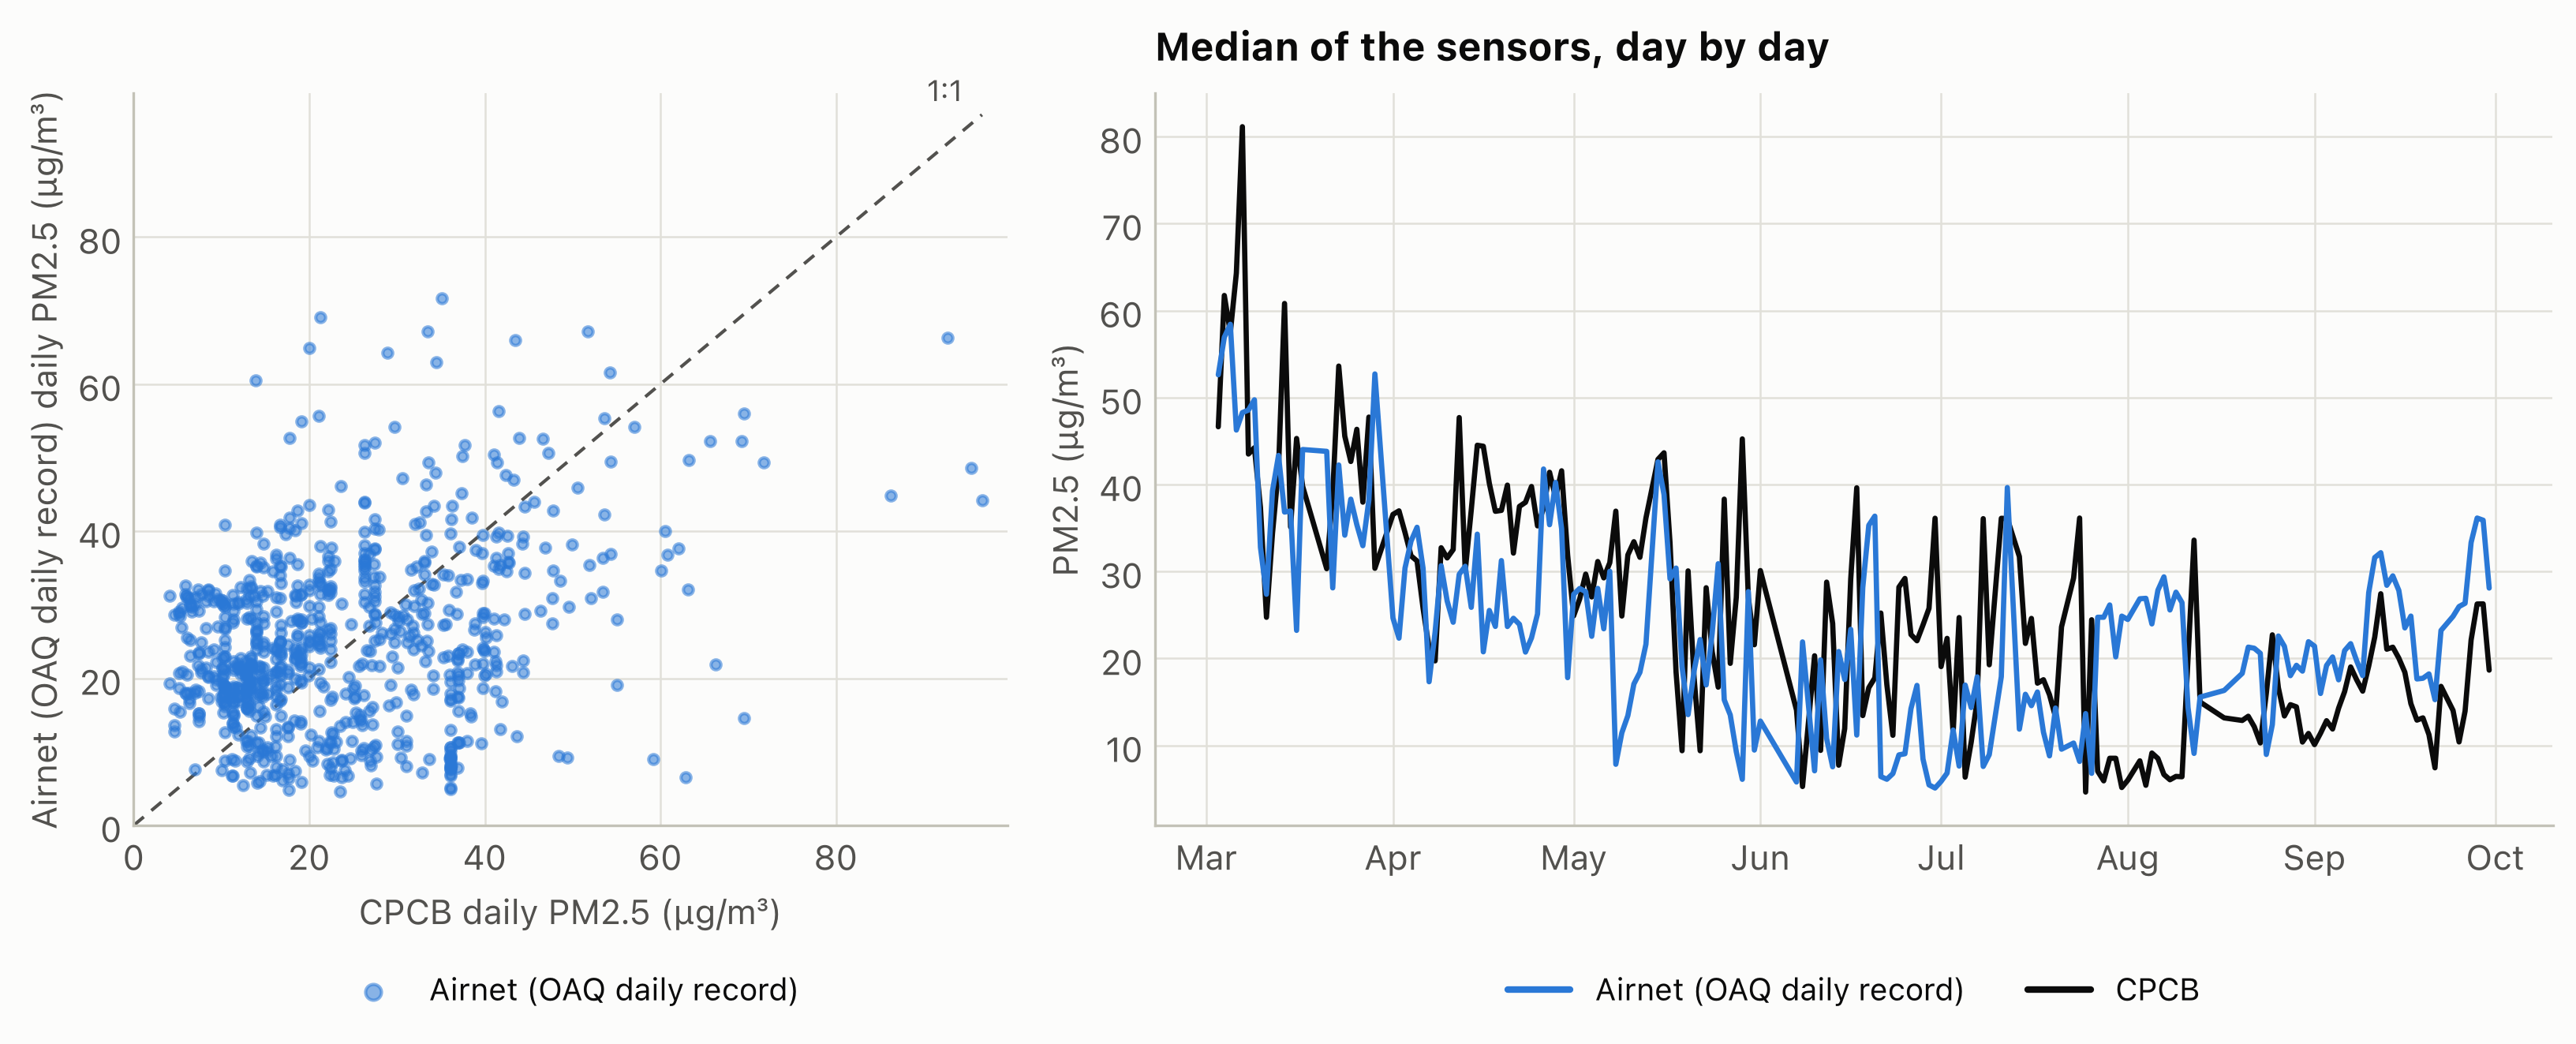

In [12]:
plot_sensor_vs_reference(
    both,
    value="record",
    sensor_label="Airnet (OAQ daily record)",
    reference_label="CPCB",
)

A daily record is one 15-minute reading. Thus, a daily record has more noise than the daily mean of the same day.

## Summary

The tables in this notebook give the numbers. If you run the notebook again, it updates the numbers.

- The low-cost OAQ sensors are Airnet sensors in Bengaluru and Aurassure sensors in smaller cities. Some of these cities have no CPCB station (section 1).
- The first-day table in section 2 gives the history of each provider.
- Section 2 gives the plausibility flags. It also lists the sensors with temperatures of more than 50 °C.
- From the first days of March 2026, a daily record of OAQ is usually the last 15-minute reading of the day, not the mean (section 3). But the 15-minute readings of OAQ for the CPCB copy are equal to the data of CPCB (section 3). Use `readings_mean` or `daily_means` to get daily values.
- For the comparison of Airnet and CPCB, refer to the accuracy table and the plots in section 4. For completeness, precision and humidity, refer to the quality notebook.